## Tiền Xử Lý Dữ Liệu và Phân Chia Tập Dữ Liệu Chống Rò Rỉ (GTSRB)

Báo cáo quy trình thu thập, tiền xử lý hình ảnh và phân chia tập dữ liệu cho bài toán nhận diện 43 lớp biển báo giao thông Đức (German Traffic Sign Recognition Benchmark - GTSRB).

**Mục tiêu chính**:
1. Chuẩn hóa hình ảnh: Cắt vùng quan tâm (ROI), cân bằng sáng thích ứng cục bộ (CLAHE trên không gian màu LAB), và resize về kích thước chuẩn 48x48.
2. Ngăn ngừa rò rỉ dữ liệu (Data Leakage): Phân chia Train/Validation theo chuỗi video (Track) bằng `StratifiedGroupKFold`.
3. Tối ưu hóa hiệu năng: Lưu trữ mảng tiền xử lý dưới dạng cache nhị phân `.npy` phục vụ truy xuất tốc độ cao qua cơ chế Memory Mapping (`mmap`).

## 1. Khởi tạo Môi trường và Thiết lập Cấu hình Tham số

### 1.1. Khởi tạo thư viện và thiết lập thư mục làm việc
Toàn bộ đường dẫn trong notebook được thiết lập tương đối từ thư mục gốc của dự án.

In [1]:
import os
import csv
from pathlib import Path
import urllib.request
import zipfile

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

# Thiết lập thư mục gốc của dự án
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
print(f"Thư mục làm việc hiện tại: {Path.cwd()}")

Thư mục làm việc hiện tại: d:\code\Python\DSEB_ex\DL\gtsrb-model-comparison


### 1.2. Thiết lập các cờ điều khiển và đường dẫn lưu trữ
Các cờ điều khiển cho phép người dùng lựa chọn giữa việc xử lý lại từ đầu hoặc tái sử dụng các tệp tin đã tạo sẵn:
* `FORCE_DOWNLOAD`: Tải lại tệp zip gốc từ archive Đại học Bochum.
* `FORCE_REPROCESS`: Chạy lại toàn bộ quy trình tiền xử lý và tạo lại cache `.npy`.

In [ ]:
FORCE_DOWNLOAD = False      # Đặt True nếu cần tải lại dữ liệu thô
FORCE_REPROCESS = False     # Đặt True nếu cần tiền xử lý và tạo lại cache

RAW_DIR = Path("data/raw")
OUT_DIR = Path("data/processed")
INDEX_CSV = OUT_DIR / "index.csv"
IMG_SIZE = 48

OUT_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

## 2. Thu Thập Dữ Liệu Gốc

### 2.1. Cấu trúc dữ liệu và kho lưu trữ chính thức
Dữ liệu gốc được tải từ kho lưu trữ ERDA (Đại học Bochum), bao gồm 3 tệp lưu trữ:
1. `GTSRB_Final_Training_Images.zip`: 39.209 ảnh huấn luyện chia vào 43 thư mục lớp.
2. `GTSRB_Final_Test_Images.zip`: 12.630 ảnh kiểm thử chính thức.
3. `GTSRB_Final_Test_GT.zip`: Tệp nhãn mặt đất (`GT-final_test.csv`) của tập kiểm thử.

*Lưu ý*: Không sử dụng bộ tải tự động của `torchvision.datasets.GTSRB` do bộ đó chỉ chứa 26.640 ảnh huấn luyện rút gọn.

In [3]:
BASE_URL = "https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370"
ARCHIVES = {
    "GTSRB_Final_Training_Images.zip": "full_train",
    "GTSRB_Final_Test_Images.zip": "full_test",
    "GTSRB_Final_Test_GT.zip": "full_test_gt",
}

def download_gtsrb(root: Path = RAW_DIR) -> None:
    """Tải và giải nén 3 tập tin lưu trữ gốc từ ERDA nếu chưa tồn tại."""
    root.mkdir(parents=True, exist_ok=True)
    for zip_name, out_name in ARCHIVES.items():
        out_dir = root / out_name
        if out_dir.exists() and any(out_dir.rglob("*")):
            print(f"  [Bỏ qua] Đã tồn tại thư mục {out_name}")
            continue
        print(f"  [Đang tải] {zip_name} ...")
        zip_path = root / zip_name
        urllib.request.urlretrieve(f"{BASE_URL}/{zip_name}", zip_path)
        out_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(out_dir)
        zip_path.unlink(missing_ok=True)
        print(f"  [Hoàn tất] Giải nén vào {out_dir}")

### 2.2. Kiểm tra trạng thái dữ liệu thô
Thực thi kiểm tra dữ liệu; nếu cờ `FORCE_DOWNLOAD = True` hoặc chưa có dữ liệu, hàm sẽ tự động tải về.

In [4]:
if FORCE_DOWNLOAD:
    print("Bắt đầu tải dữ liệu thô...")
    download_gtsrb(RAW_DIR)
else:
    print("Sử dụng dữ liệu thô có sẵn trong thư mục data/raw (nếu chưa có, đặt FORCE_DOWNLOAD = True).")

Bắt đầu tải dữ liệu thô...
  [Đang tải] GTSRB_Final_Training_Images.zip ...


  [Hoàn tất] Giải nén vào data\raw\full_train
  [Đang tải] GTSRB_Final_Test_Images.zip ...
  [Hoàn tất] Giải nén vào data\raw\full_test
  [Đang tải] GTSRB_Final_Test_GT.zip ...
  [Hoàn tất] Giải nén vào data\raw\full_test_gt


## 3. Xây Dựng Bảng Siêu Dữ Liệu (Metadata Index)

### 3.1. Phân tích cấu trúc tệp nhãn và định dạng tên tệp
Các tệp nhãn của GTSRB dùng dấu chấm phẩy (`;`) làm ký tự phân cách.
Định dạng tên tệp trong tập train có dạng: `00005_00017.ppm`, trong đó:
* Phần số đầu (`00005`): Định danh Track (chuỗi video cùng một biển báo vật lý).
* Phần số sau (`00017`): Thứ tự khung hình (Frame) trong chuỗi 30 khung hình liên tiếp.

In [5]:
def _find_dir(root: Path, *candidates: str) -> Path:
    """Tìm thư mục dữ liệu theo danh sách tên ứng viên tương thích."""
    for c in candidates:
        if (root / c).is_dir():
            return root / c
    raise FileNotFoundError(f"Không tìm thấy thư mục dữ liệu trong {root}")

def _read_gt(csv_path: Path) -> list[dict]:
    """Đọc tệp annotation CSV định dạng dấu chấm phẩy của GTSRB."""
    with open(csv_path, encoding="utf-8", newline="") as fh:
        return list(csv.DictReader(fh, delimiter=";"))

### 3.2. Hàm thu thập siêu dữ liệu toàn bộ tập ảnh
Hàm `build_index` duyệt qua toàn bộ 43 thư mục train và thư mục test chính thức để tạo ra DataFrame tổng hợp gồm tọa độ ROI, nhãn lớp, và mã Track.

In [6]:
def build_index(root: Path = RAW_DIR) -> pd.DataFrame:
    """Thu thập thông tin đường dẫn, ROI, class_id và track_id cho 51.839 ảnh."""
    rows: list[dict] = []

    # 1. Tập huấn luyện (43 lớp)
    train_dir = _find_dir(root, "full_train/GTSRB/Final_Training/Images", "GTSRB/Final_Training/Images")
    class_dirs = sorted(d for d in train_dir.iterdir() if d.is_dir())
    if len(class_dirs) != 43:
        raise RuntimeError(f"Yêu cầu 43 thư mục lớp, phát hiện {len(class_dirs)}")

    for class_dir in class_dirs:
        class_id = int(class_dir.name)
        gt_file = next(class_dir.glob("GT-*.csv"))
        for rec in _read_gt(gt_file):
            track, _, frame = Path(rec["Filename"]).stem.partition("_")
            rows.append({
                "path": (class_dir / rec["Filename"]).as_posix(),
                "class_id": class_id,
                "track_id": int(track),
                "frame_id": int(frame),
                "roi_x1": int(rec["Roi.X1"]), "roi_y1": int(rec["Roi.Y1"]),
                "roi_x2": int(rec["Roi.X2"]), "roi_y2": int(rec["Roi.Y2"]),
                "source": "train",
            })

    n_train = len(rows)

    # 2. Tập kiểm thử chính thức (12.630 ảnh)
    test_dir = _find_dir(root, "full_test/GTSRB/Final_Test/Images", "GTSRB/Final_Test/Images")
    test_gt = next(root.rglob("GT-final_test.csv"))
    for pos, rec in enumerate(_read_gt(test_gt)):
        rows.append({
            "path": (test_dir / rec["Filename"]).as_posix(),
            "class_id": int(rec["ClassId"]),
            "track_id": -1 - pos,  # Đánh số âm riêng biệt tránh trùng track train
            "frame_id": 0,
            "roi_x1": int(rec["Roi.X1"]), "roi_y1": int(rec["Roi.Y1"]),
            "roi_x2": int(rec["Roi.X2"]), "roi_y2": int(rec["Roi.Y2"]),
            "source": "test_official",
        })

    frame = pd.DataFrame(rows)
    print(f"Tổng hợp thành công: {n_train} ảnh train + {len(rows)-n_train} ảnh test = {len(rows)} ảnh.")
    return frame

## 4. Phân Chia Tập Train/Validation Theo Track (Ngăn Chặn Rò Rỉ Dữ Liệu)

### 4.1. Phân tích hiện tượng rò rỉ dữ liệu trong GTSRB
Mỗi biển báo vật lý được ghi hình trong 30 khung hình liên tiếp. Khung hình số 12 và khung hình số 13 gần như giống hệt nhau về góc nhìn và ánh sáng.
* Nếu phân chia ngẫu nhiên (Random Split theo ảnh): Khung hình 12 rơi vào Train, khung hình 13 rơi vào Validation. Mô hình chỉ cần ghi nhớ (memorize) mẫu đã thấy thay vì học cách khái quát (generalize), dẫn đến độ chính xác Validation cao giả tạo.
* Giải pháp: Sử dụng `StratifiedGroupKFold` với nhóm $g = (class\_id, track\_id)$ để đảm bảo toàn bộ 30 khung hình của cùng một biển báo chỉ thuộc về Train hoặc chỉ thuộc về Validation.

In [7]:
def make_split(frame: pd.DataFrame, val_ratio: float = 0.2, seed: int = 42) -> pd.DataFrame:
    """Phân chia tập train thành train/val theo track bằng StratifiedGroupKFold."""
    frame["split"] = "test"
    pool = frame[frame["source"] == "train"]
    labels = pool["class_id"].to_numpy()
    groups = np.array([f"{c}_{t}" for c, t in zip(pool["class_id"], pool["track_id"])])

    n_splits = max(2, round(1.0 / val_ratio))
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    train_pos, val_pos = next(splitter.split(pool, labels, groups))

    idx = pool.index.to_numpy()
    frame.loc[idx[train_pos], "split"] = "train"
    frame.loc[idx[val_pos], "split"] = "val"

    # Kiểm tra an toàn toán học: Giao của hai tập track phải bằng rỗng
    def track_keys(part):
        return {f"{c}_{t}" for c, t in zip(part["class_id"], part["track_id"])}

    tr, va = frame[frame.split == "train"], frame[frame.split == "val"]
    shared = track_keys(tr) & track_keys(va)
    assert len(shared) == 0, f"LỖI RÒ RỈ DỮ LIỆU: Phát hiện {len(shared)} track chung giữa train và val!"

    counts = frame["split"].value_counts()
    print(f"Phân chia hoàn tất: train={counts.get('train', 0)}, val={counts.get('val', 0)}, test={counts.get('test', 0)}")
    print(f"Xác nhận chống rò rỉ: Số track dùng chung = {len(shared)} (Đạt tiêu chuẩn an toàn).")
    return frame

## 5. Thuật Toán Xử Lý Hình Ảnh (ROI Crop & CLAHE)

### 5.1. Cơ sở lý thuyết của các phép biến đổi
1. **Cắt ROI nới lề 10% (`margin=0.10`)**: Cắt sát mép có nguy cơ làm mất viền biển báo (viền đỏ của biển cấm mang đặc trưng quyết định). Nới lề 10% giúp giữ trọn vẹn hình thái biển báo đồng thời loại bỏ phần lớn nhiễu nền môi trường.
2. **Cân bằng sáng thích ứng CLAHE trên kênh L (không gian màu LAB)**:
   * Cân bằng trực tiếp trên từng kênh RGB độc lập sẽ làm thay đổi tỉ lệ màu, dẫn đến đổi màu biển báo (sai lệch bản chất quy ước giao thông).
   * Không gian màu LAB tách biệt cường độ sáng ($L$) khỏi hai trục màu ($A, B$). Áp dụng CLAHE trên kênh $L$ giúp biển báo rõ nét dưới các điều kiện thiếu sáng hoặc ngược sáng mà vẫn giữ nguyên màu sắc nguyên bản.
3. **Phép nội suy kích thước**: Thu nhỏ dùng `INTER_AREA` (chống răng cưa), phóng to dùng `INTER_CUBIC` (mượt mà biên).

In [8]:
_CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def _process_one(path: str, roi: tuple[int, int, int, int], size: int) -> np.ndarray:
    """Thực hiện đọc ảnh, cắt ROI nới lề 10%, CLAHE trên kênh L và resize về size x size."""
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(f"Không thể đọc ảnh: {path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    # 1. Cắt ROI nới lề 10%
    x1, y1, x2, y2 = roi
    h, w = rgb.shape[:2]
    px, py = int((x2 - x1) * 0.10), int((y2 - y1) * 0.10)
    x1, y1 = max(0, x1 - px), max(0, y1 - py)
    x2, y2 = min(w, x2 + px), min(h, y2 + py)
    if x2 > x1 and y2 > y1:
        rgb = rgb[y1:y2, x1:x2]

    # 2. CLAHE trên kênh L (LAB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = _CLAHE.apply(lab[:, :, 0])
    rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 3. Resize với thuật toán nội suy phù hợp
    shrink = size < rgb.shape[0] or size < rgb.shape[1]
    interp = cv2.INTER_AREA if shrink else cv2.INTER_CUBIC
    return cv2.resize(rgb, (size, size), interpolation=interp)

## 6. Xây Dựng Bộ Đệm Cache (`.npy`)

### 6.1. Hàm tạo mảng NumPy cache
Toàn bộ 51.839 ảnh được xử lý trước và đóng gói thành một mảng định dạng `(N, 48, 48, 3)` kiểu `uint8`. Điều này giúp quá trình huấn luyện nạp trực tiếp vào RAM/Bộ nhớ chia sẻ trong tích tắc thay vì phải giải mã từng file ảnh `.ppm` trên ổ đĩa mỗi epoch.

In [9]:
def build_cache(frame: pd.DataFrame, size: int = IMG_SIZE) -> np.ndarray:
    """Xử lý toàn bộ ảnh theo thứ tự index.csv và đóng gói thành mảng numpy uint8."""
    total = len(frame)
    out = np.zeros((total, size, size, 3), dtype=np.uint8)
    for i, row in enumerate(frame.itertuples()):
        roi = (row.roi_x1, row.roi_y1, row.roi_x2, row.roi_y2)
        out[i] = _process_one(row.path, roi, size)
        if (i + 1) % 10000 == 0 or (i + 1) == total:
            print(f"  Tiến độ: {i + 1}/{total} ảnh ({(i+1)/total*100:.1f}%)")
    return out

### 6.2. Điều phối lưu trữ và nạp tài nguyên
Kiểm tra sự tồn tại của `index.csv` và `images_48_clahe.npy`:
* Nếu các tệp đã có và `FORCE_REPROCESS = False`, notebook sẽ nạp và xác nhận thông số mà không cần tính toán lại.
* Nếu chưa có hoặc `FORCE_REPROCESS = True`, quy trình tiền xử lý đầy đủ sẽ được thực thi.

In [12]:
cache_path = OUT_DIR / f"images_{IMG_SIZE}_clahe.npy"

if not FORCE_REPROCESS and INDEX_CSV.exists() and cache_path.exists():
    print(f"[Tài nguyên sẵn sàng] Đã phát hiện {INDEX_CSV} và {cache_path}.")
    frame = pd.read_csv(INDEX_CSV)
    cache = np.load(cache_path, mmap_mode="r")
    print(f"  Số dòng metadata: {len(frame)}")
    print(f"  Kích thước mảng cache: {cache.shape}, Kiểu dữ liệu: {cache.dtype}, Dung lượng: {cache.nbytes / 1e6:.1f} MB")
else:
    print("[Thực thi] Bắt đầu xây dựng metadata index...")
    frame = build_index(RAW_DIR)
    frame = make_split(frame)
    frame.to_csv(INDEX_CSV, index=False)
    print(f"Đã lưu bảng siêu dữ liệu vào {INDEX_CSV}")

    print("[Thực thi] Bắt đầu xử lý ảnh và tạo cache numpy...")
    cache = build_cache(frame, IMG_SIZE)
    np.save(cache_path, cache)
    print(f"Đã lưu cache thành công vào {cache_path} ({cache.nbytes / 1e6:.1f} MB).")

[Tài nguyên sẵn sàng] Đã phát hiện data\processed\index.csv và data\processed\images_48_clahe.npy.
  Số dòng metadata: 51839
  Kích thước mảng cache: (51839, 48, 48, 3), Kiểu dữ liệu: uint8, Dung lượng: 358.3 MB


## 7. Trực Quan Hóa Kiểm Tra Thực Nghiệm

### 7.1. Đánh giá chất lượng ảnh trước và sau tiền xử lý
Hiển thị so sánh 8 mẫu ảnh ngẫu nhiên giữa ảnh gốc và ảnh sau quy trình cắt ROI kết hợp CLAHE.

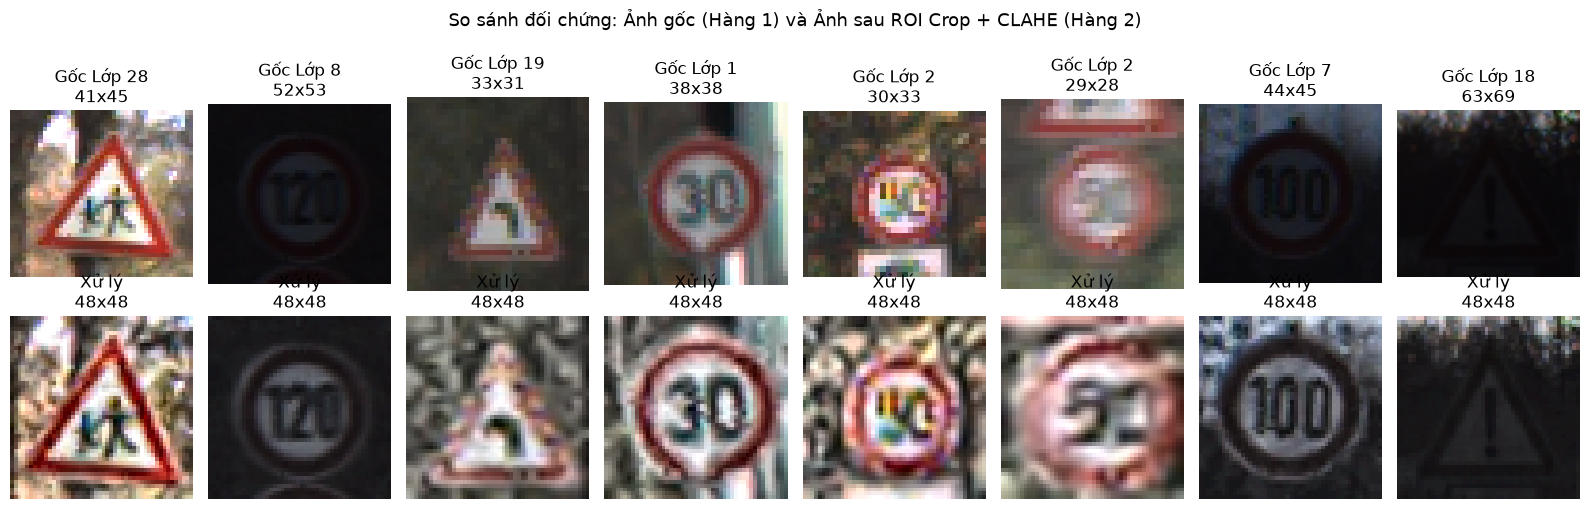

In [13]:
sample_indices = np.random.choice(len(frame), size=8, replace=False)

plt.figure(figsize=(16, 5))
for idx, i in enumerate(sample_indices):
    row = frame.iloc[i]
    # Ảnh gốc
    raw_img = cv2.cvtColor(cv2.imread(row["path"]), cv2.COLOR_BGR2RGB)
    plt.subplot(2, 8, idx + 1)
    plt.imshow(raw_img)
    plt.title(f"Gốc Lớp {row['class_id']}\n{raw_img.shape[0]}x{raw_img.shape[1]}")
    plt.axis("off")

    # Ảnh sau tiền xử lý từ cache
    proc_img = cache[i]
    plt.subplot(2, 8, idx + 9)
    plt.imshow(proc_img)
    plt.title(f"Xử lý\n48x48")
    plt.axis("off")

plt.suptitle("So sánh đối chứng: Ảnh gốc (Hàng 1) và Ảnh sau ROI Crop + CLAHE (Hàng 2)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()